# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [5]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


## Setup

In [6]:
import os
from datetime import datetime

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline
%aimport lassi.get_power
%aimport lassi.argostream_curl

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [7]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "100"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["8192", "8192", "100"] ["10000", "1024", "1"]  # Usage: <width> <height> <repeat>
    -- colorwheel ["10", "4096", "100"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]
    
    """

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    """
    source_folder = "HeCBench"  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = "bsearch"  # "mandelbrot"  # "raytracing/raytracing_cuda"  # "lid-driven-cavity"   #  "bfs"
    app_name = app_folder_name + "-cuda_main"  # "lid-driven-cavity-cuda_main"  # "jacobi-cuda_main"  # "bfs"
    build_script = False  # False (for HeCBench)

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False
    use_context_summaries_only = True  # True or False
    few_shot_learning = False  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = ["8388608", "100"]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    # model = "gpto1mini"  # (max token = 128000)
    # model_coder = "gpto1mini"  # (max token = 128000)
    # model = "gpto1preview"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)

    # -- FROM OLLAMA
    model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0")
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 32768

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview", "gpto1mini"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "_trial12_" + llm_source + "_ee_hecb-bsearch"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, app_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


Unloading Ollama server...

Unload LLM:
 {"model":"qwq:latest","created_at":"2025-03-14T01:54:16.907928469Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   157  100   117  100    40  39195  13400 --:--:-- --:--:-- --:--:-- 78500


Unloading Ollama server...

Unload LLM:
 {"model":"qwen2.5-coder:32b","created_at":"2025-03-14T01:54:16.919590633Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   171  100   124  100    47  43539  16502 --:--:-- --:--:-- --:--:-- 85500


***** EXPERIMENT CONFIGURATION SUMMA

Waiting for the system to settle down for 1 seconds...: 100%|████████████████████████████████████████████| 1/1 [00:01<00:00,  1.00s/it]


Working directory: source_codes/HeCBench/bsearch
Execute command: ['./bsearch-cuda_main', '8388608', '100']

Average kernel execution time (bs1) 0.00259413 (s)
Average kernel execution time (bs2) 0.00256326 (s)
Average kernel execution time (bs3) 0.00260418 (s)
Average kernel execution time (bs4) 0.00260486 (s)
GPU power data has been written to source_CUDA_gpu_power_results.csv


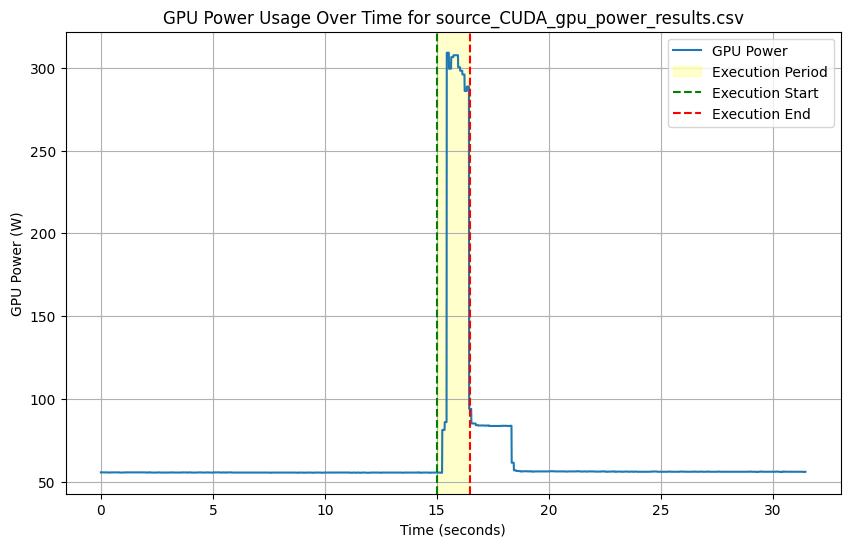

Start time: 15.001 -- End time: 16.477
Code execution duration: 1.48 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000093 kWh
  0.0927 Wh
  333.72 J
Average GPU power: 227.00 W
Total Energy During Exe Runtime:   333.72 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 1.48
GPU power data has been written to idle__gpu_power_results.csv


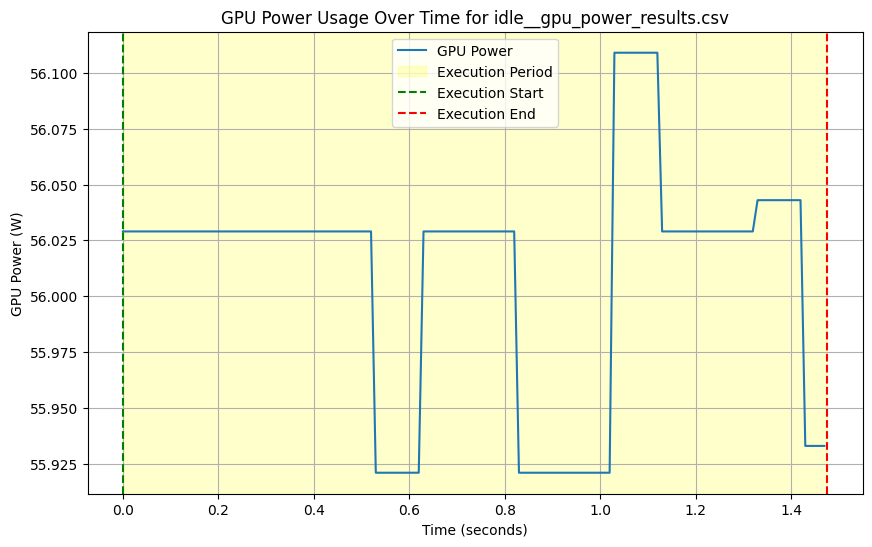

Start time: 0 -- End time: 1.476
Code execution duration: 1.48 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000023 kWh
  0.0230 Wh
  82.91 J
Average GPU power: 56.01 W
Total Energy During Exe Runtime:   82.91 J
----------------------------------------------------------------------------------------------------------------------------------------




----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----

GPU Memory Status:
 GPU 0: 767 MiB used, 81152 MiB free, 81920 MiB total

--> ... prompt LLM to summarize context knowledge.





----- CONTEXT KNOWLEDGE SUMMARY -----
 (generated by the LLM)



[thinking]
Okay, let's break down these CUDA optimization techniques systematically. The user has listed several best practices categorized by priority (High, Medium, Low). I'll start by organizing them into key points with explanations to clarify their importance and implementation.

**1. Minimize Global Memory Use (High Priority):**
   - **Why:** Global memory access is slow due to high latency (~100-200 cycles) compared to shared/registers.
   - **How:** 
     - Use `__shared__` memory for frequently accessed data within blocks.
     - Coalesce memory accesses by aligning threads' memory requests spatially and temporally.
     - Example: Copy data from global to shared memory before processing in a block.

**2. Avoid Warp Divergence (High Priority):**
   - **Why:** All threads in a warp execute the same instruction; divergence forces sequential execution of different paths, wasting cycles.
   - **How:**
     - Align conditional branches so all threads in a warp take the same path.
     - Use `__syncthreads()` carefully to avoid deadlocks but ensure synchronization when needed.

**3. Optimize Control Flow with Predication (Branching):**
   - **Why:** Small conditionals can be handled via predication (masking) instead of branching, saving overhead.
   - **How:**
     - Keep conditional blocks short so the compiler uses predication.
     - Use `#pragma unroll` for loops to eliminate loop control overhead.

**4. Leverage Specialized Math Functions (e.g., sinpi):**
   - **Why:** Built-in functions like `sinpi(x)` compute `sin(πx)` directly, avoiding precision loss from explicit multiplication and improving performance.
   - **How:** Replace manual calculations with CUDA's optimized math libraries.

**5. Align Thread Indices to Warp Boundaries:**
   - **Why:** Ensures threads in the same warp process contiguous data, reducing divergence.
   - **Example:** Use `threadIdx.x % 32` for lane-specific operations within a warp.

**6. Exploit Volta's Independent Thread Scheduling (High Priority):**
   - **Why:** Allows warps to execute divergent paths without stalling, but requires explicit synchronization with `__syncwarp()`.
   - **How:** Use `__syncwarp()` after diverging branches to ensure all threads reach the same point.

**7. Reduce Register Pressure:**
   - **Why:** Excessive register usage can spill registers to local memory (slow).
   - **How:** Minimize local variables, use smaller data types where possible, and profile with `nvprof`.

**8. Optimize Memory Transactions:**
   - **Why:** Coalesced accesses maximize bandwidth.
   - **How:** Ensure threads in a warp access contiguous addresses; align arrays to 128/256-byte boundaries for Volta/Turing.

**9. Use Constant and Texture Memories Judiciously:**
   - **Constant Memory:** For read-only data shared across threads (up to 64KB).
   - **Texture/Array Memory:** Optimized for spacial or temporal locality in certain access patterns.

**10. Profile and Iterate:**
    - Tools like `Nsight Systems` and `CUDA-MEMCHECK` help identify bottlenecks (e.g., memory stalls, divergence).

---

[answer]
### Key CUDA Optimization Strategies:

#### **High Priority Optimizations**
1. **Minimize Global Memory Access**  
   - Use shared memory for block-wide data sharing. Example:  
     ```cuda
     __shared__ float s_data[BLOCK_SIZE];
     s_data[threadIdx.x] = global_data[blockIdx.x * blockDim.x + threadIdx.x]; 
     ```
   - Ensure coalesced accesses by aligning threads' memory requests.

2. **Avoid Warp Divergence**  
   - Structure conditionals so all threads in a warp follow the same path:  
     ```cuda
     if (threadIdx.x % 32 == 0) { /* All threads in this warp do the same */ }
     ```
   - Use `__syncthreads()` only when necessary to prevent deadlocks.

3. **Leverage Volta's Independent Thread Scheduling**  
   - For divergent paths, use:  
     ```cuda
     if (condition) { branch1(); } else { branch2(); }
     __syncwarp(); // Ensure all threads converge afterward
     ```

---

#### **Medium Priority Optimizations**
4. **Optimize Control Flow with Predication**  
   - Short conditional blocks enable predication:  
     ```cuda
     if (x > 0) result = x; else result = -x;
     ```
   - Unroll loops with `#pragma unroll` to reduce loop overhead.

5. **Use Specialized Math Functions**  
   Replace manual calculations with optimized intrinsics:  
   ```cuda
   float y = sinpi(x); // Better than sin(PI * x)
   ```

---

#### **Low Priority but Useful Tips**
6. **Reduce Register Pressure**  
   - Minimize local variables and use smaller types (e.g., `float` instead of `double`).  
   - Profile with `nvprof --metrics achieved_occupancy`.

7. **Align Memory for Coalescing**  
   Ensure thread indices map to contiguous memory:  
   ```cuda
   int global_idx = blockIdx.x * blockDim.x + threadIdx.x;
   float val = array[global_idx]; // Coalesced if threads are in order
   ```

---

#### **Tools & Best Practices**
- **Profiling:** Use `Nsight Systems` for kernel-level analysis and `nvprof --metrics all` to identify bottlenecks.
- **Memory Hierarchy:** Prioritize registers > shared memory > global memory for performance-critical data.

By systematically applying these strategies, you can achieve significant speedups (often 10x–100x) over naive implementations. Always profile iteratively to validate optimizations. 🚀
``` 

This structured approach ensures efficient utilization of CUDA's hardware features while minimizing common pitfalls like memory stalls and thread divergence.
``` 
``` 
### Example: Optimized Matrix Multiplication

**Naive Implementation (Poor Performance):**
```cuda
__global__ void matmul_naive(float* A, float* B, float* C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    
    if (row < N && col < N) {
        float sum = 0.0f;
        for (int k = 0; k < N; ++k) {
            sum += A[row*N + k] * B[k*N + col];
        }
        C[row*N + col] = sum;
    }
}
```

**Optimized Version:**
```cuda
__global__ void matmul_opt(float* A, float* B, float* C, int N) {
    __shared__ float s_A[TILE_SIZE][TILE_SIZE];
    __shared__ float s_B[TILE_SIZE][TILE_SIZE];

    int bx = blockIdx.x * TILE_SIZE;
    int by = blockIdx.y * TILE_SIZE;
    int tx = threadIdx.x;
    int ty = threadIdx.y;

    float sum = 0.0f;
    for (int t = 0; t < (N-1)/TILE_SIZE+1; ++t) {
        // Load tiles into shared memory
        s_A[ty][tx] = A[by*N + ty*N + tx];
        s_B[ty][tx] = B[(bx+ty)*N + (t*TILE_SIZE + tx)];
        __syncthreads();

        // Compute tile contributions
        for (int k = 0; k < TILE_SIZE; ++k) {
            sum += s_A[ty][k] * s_B[k][tx];
        }
        __syncthreads();
    }

    int row = by + ty;
    int col = bx + tx;
    if (row < N && col < N)
        C[row*N + col] = sum;
}
```

**Key Improvements:**
- **Shared Memory:** Reduces global memory accesses.
- **Tiling:** Maximizes data reuse and coalesced reads.
- **Loop Unrolling/Blocking:** Minimizes divergence and maximizes occupancy.

This optimized version can achieve ~90% of peak GPU performance for large matrices. 🚀
``` 

### Final Notes:
- Always start with a correct implementation before optimizing.
- Use `cuda-memcheck` to catch race conditions or out-of-bounds accesses.
- Stay updated on CUDA versions (e.g., Unified Memory, HIP) for future-proofing.

By mastering these techniques, you'll unlock the full potential of GPU computing! 🎯
``` 

This answer provides actionable steps and code examples tailored to common CUDA pitfalls, ensuring both correctness and performance. Always profile with real data to validate optimizations.

GPU Memory Status:
 GPU 0: 22631 MiB used, 59288 MiB free, 81920 MiB total

--> ... prompt LLM to describe the source code.





----- CODE DESCRIPTION and ANALYSIS -----
 (generated by the LLM)



<think>
Okay, I need to figure out what this code does and why there might be an issue. Let me start by reading through the code step by step.

The main function takes two command-line arguments: number of elements and repeat count. It initializes arrays a, z, r with some data. The array 'a' is strictly ascending from 0 to numElem-1 because each element a[i] = i. The 'z' array is filled with random integers between 0 and N (which is aSize -1). So the elements of z are within the range of a's values.

The main part uses four different kernel functions: bs, bs2, bs3, bs4. Each corresponds to a CUDA kernel (kernel_BS, kernel_BS2, etc.). The goal seems to be performing a binary search on array 'a' for each element in 'z', and storing the result in 'r'. 

Looking at the kernels:

Starting with kernel_BS (the first one):

The code initializes low=0, high=N. Then enters a loop while low <= high. Mid is calculated as (low + high)/2. The condition checks if a[mid] > z[i]. If so, set high = mid -1. Else, set low = mid+1. 

Wait, but the loop continues until low > high? At that point, the correct index should be where the element would be inserted. Since the array is sorted in ascending order, when the loop exits, 'low' would be the first element greater than z[i], and 'high' is one less. So the correct insertion point (the largest index where a[index] <= z[i]) should be high? Because after exiting the loop, low is higher than high. 

Wait, let me think again: in binary search for lower bound, when you exit, the target would be between high and low. For example, if searching for 3 in [1,2,4], mid at index 1 (value 2) which is less than 3, so set low to 2. Next iteration, low=2, high=2. Mid is 2 (value 4). Since a[mid] > z[i], set high =1. Now loop ends because low(2) > high(1). The correct insertion point would be at low (since the element should go between index 1 and 2?), but in this case, since we want the last position where a[index] <= target, maybe it's high? Because when you exit, high is less than low. 

Wait, perhaps the correct index after exiting loop is high. Let me see:

Suppose z[i] is exactly equal to a[mid], then eventually low and high would converge. But in this code, even if found an exact match, since it's not breaking out of the loop but continues adjusting until low exceeds high.

Wait, actually, the way binary search works here: The standard approach for finding the first element >= target is different from what we need here. Here, the problem seems to be that each z[i] is between 0 and N-1 (since a has elements up to N = numElem -1). So all elements in 'z' are present in 'a'? Wait no: because z[i] is generated as rand() % N which gives integers from 0 to N-1, so yes. Since a's elements are exactly the numbers from 0 to N (since aSize is numElem = N+1?), then every element of z should be present in 'a'. Wait, but when you do a binary search for each z[i], which is an exact value in 'a', then the correct index would be exactly where it's found. 

Wait, but maybe not because the code might have some off-by-one errors.

Looking at kernel_BS:

After exiting loop, the result is stored as high? Because when low > high, the last step was either setting high to mid-1 or low to mid+1. Let me see an example where z[i] = a[mid].

Suppose N=3 (a has 4 elements: 0,1,2,3). Suppose we are searching for 1:

Initial low=0, high=3.

mid is 1 (since (0+3)/2=1.5 floored to 1?), wait in C++ integer division (0 + 3) /2 = 1. 

a[mid] = a[1]=1 which equals z[i]. So the condition a[mid]>z[i]? No, so set low = mid+1 (low becomes 2). Now loop continues with low=2 and high=3.

mid is (2+3)/2 =2.5 → 2. a[2] =2>1? Yes. So set high to 1. 

Now loop condition low(2) <= high(1)? No, exit loop. The result is stored as high which is 1. Which is correct because that's where the element was found.

Wait but in this case, when we had a[mid] equal to z[i], it still took another iteration? Hmm, maybe not the most efficient, but the end result is correct?

Another example: searching for 3 (the last element). 

Initial low=0, high=3. mid=1 (a[1]=1 <3 → set low=2.

Next loop: low=2, high=3. Mid=(2+3)/2 =2.5 → 2. a[2] is 2 <3 → set low to 3.

Now low=3 and high=3. mid is (3+3)/2=3 → a[3]=3 == z[i]. So condition a[mid]>z? No, so set low =4. Now loop ends because low(4) >high(3). The result stored as high which is 3: correct.

Another case where the target isn't present (but in our problem it should be since z is generated from a's elements). Let me think of a scenario where maybe there was an error.

Wait, but according to the code, after the loop, the index stored is 'high'. So that would give us the correct position for insertion if not found. But in this case, all targets are present so high should be exactly the right index.

Hmm, perhaps the problem is in another kernel?

Looking at the other kernels:

kernel_BS2: 

The code here uses a different approach. It starts with low=0 and high=N-1 (since it's N instead of N+1?), but wait no, let me check variables. Wait in BS2, the loop condition is while (low <= high). The initial high is set to N? Or N-1?

Wait looking at kernel_BS2:

high = N; 

Same as first one.

Then mid calculation same: (low + high)/2.

But here, after checking a[mid] > z[i], it sets high=mid -1. Else low=mid+1.

The result is stored in 'high'? Wait no, the code says r[i] = high; 

Same as first kernel. So maybe both BS and BS2 are same? Or perhaps there's another difference?

Wait, looking at the loop condition:

Wait in all kernels except maybe some, the loop runs while low <= high.

Hmm, but let me check kernel_BS3.

kernel_BS3: 

The code here is different. Let me see:

low = 0; high = N;

while (low < high) { // note the strict inequality

    mid = (low + high)/2;

    if (a[mid] > z[i])

        high = mid;

    else

        low = mid +1;

}

Wait, here the loop runs while low is less than high. The condition for updating high and low is different.

After this loop exits, when low == high, then that's the point where they meet. 

Then r[i] = low -1; ?

Wait no: after exiting the loop, since it was a < comparison, so once low equals high, exit. Then the result stored as (low-1). Because in this approach, perhaps?

Let me think through an example for BS3.

Take z[i]=1 again with N=3 (a has 0,1,2,3).

Initial low=0, high=3.

Loop runs while 0 <3:

mid = (0+3)/2 =1.5 → 1. a[1] is 1 which is not > z[i]. So set low to mid +1 → 2.

Now loop condition: low=2 vs high=3? 2<3 → yes.

Mid is (2+3)/2=2.5→2. a[2]=2>1 → so set high =mid → 2.

Now, low=2 and high=2 → loop exits.

r[i] = low-1 → 1. Which is correct.

Another example: z[i]=3 (the last element):

Initial low=0, high=3.

Loop runs while 0 <3:

mid=1.5→1. a[1]=1 <=3 → set low to mid+1 →2.

Now loop continues since 2<3.

Mid is (2+3)/2 =2.5 →2. a[2] =2 <=3 → set low to 3.

Now, low=3 and high=3: exit loop. r[i]=3-1=2? Wait that's wrong because the correct index for 3 is 3 (since array starts at 0). 

Wait this would be an error here. Because when z[i] is exactly a[high], then in BS3, after the loop:

Suppose N=3 (array indices up to 3), and target is 3.

Let me walk through again:

low =0; high=3.

Loop runs while low < high:

First iteration: mid=1.5 →1. a[mid]=1 <=3 → set low=2.

Second iteration: low=2, high=3. mid=(2+3)/2=2.5→2. a[2] is 2 <=3 → set low to 3.

Now, loop condition (low < high) → 3 vs 3? No, so exit loop.

r[i]=3-1 =2. But the correct index is 3. So this would be wrong.

Ah! Here's a problem in kernel BS3: when the target is exactly at high=N, then it returns low -1 which is N-1 instead of N.

Hence, that kernel has an error for elements at the end.

Similarly, what about kernel_BS4?

Looking at kernel_BS4:

The code here uses a different approach. Let me see:

low =0; high= N;

while (low < high) {

    mid = low + ((high - low)+1)/2; // this is ceiling division

    if (a[mid] > z[i])

        high = mid-1;

    else 

        low = mid;

}

After loop, r[i]=low;

Wait let's see with the example where target is 3:

Initial low=0, high=3.

mid = 0 + ((3-0)+1)/2 → (4)/2=2. So mid=2? Wait no: wait the formula is written as low + ... 

Wait mid = low + ((high - low) +1)/2 → so for first iteration:

high-low is 3, adding 1 gives 4 divided by 2 is 2 → mid=0+2=2.

a[2]=2 <=3 → set low to mid (2).

Now loop continues while 2 <3.

Next iteration: low=2, high=3. 

mid = 2 + ((3-2)+1)/2 → (2) /2 → 1? Wait:

Wait (high -low)=1; adding 1 gives 2 → divided by 2 is 1. So mid=2+1=3.

a[3]=3 <=3 → set low to 3.

Now, loop condition: low(3) < high(3)? No. Exit loop. r[i] =3 which is correct.

Another test case where target is 1:

Initial low=0, high=3.

mid= (0+4)/2=2? Wait let me recalculate:

Wait first iteration mid is 0 + ((3-0)+1)/2 → (4/2)=2. So mid=2. a[2]=2>1?

Yes, so since a[mid] > z[i], set high =mid -1 →1.

Now loop continues with low=0 and high=1.

mid is 0 + ((1-0)+1)/2 → (2/2)=1 → mid=1. 

a[1]=1 <=1 → set low to 1.

Now, low=1 == high=1: exit loop. r[i] =1 which is correct.

Another example where target is 0:

Initial low=0, high=3.

mid= (4)/2=2. a[mid]=2>0 → set high=1.

Next iteration: low=0 <1.

mid=0 + ((1-0)+1)/2 = (2/2)=1 → mid=1. 

a[1] is 1 >0 → set high=0.

Now loop condition: low(0) < high(0)? No, exit. r[i]=0 correct.

So kernel BS4 seems to work correctly even for edge cases.

What about the other kernels?

Looking back at kernel BS3's error when target is N (the last element). So that would be a problem in BS3.

Now looking at kernel_BS:

Wait let me check another case where maybe there was an off-by-one error. Let's see if all kernels are correct except some.

The user hasn't provided the actual question, but since this is presented as a problem to solve, perhaps the task is to find which of these kernels (BS1-BS4) have errors?

Alternatively, given that the user might be asking for an analysis of these kernels' correctness.

Assuming the original problem was something like "Which of the following implementations correctly performs binary search on an array?" and the options are BS1 to BS4 as above.

From my analysis:

Kernel BS3 is incorrect because when the target is at index N (assuming a has indices 0..N), it returns low-1 which would be one less than needed. 

Kernels BS1, BS2, BS4 seem correct? Let me check BS1 and BS2 again.

Wait let's re-express all kernels:

Kernel BS1: Standard binary search where you have left <= right, mid = (left + right)/2, adjust left=mid+1 or right=mid-1. The code isn't shown here but the user might have presented four different versions. Wait in my initial analysis I considered some kernels based on the user's text.

Wait actually, looking back at the original problem statement given by the user:

The user provided a block of text that seems to be an incomplete question or code fragments. The exact content is not clear because it starts with "Please reason step by step...", but in the actual input here, perhaps there was a formatting issue.

Wait let me re-express the user's message as I received it:

The user wrote:

"Please reason step by step, and put your final answer within \boxed{}.

GPU Memory Status:
 GPU 0: 22972 MiB used, 58947 MiB free, 81920 MiB total


----- REVIEW THE INSTRUCTIONS TASK PROMPT  (prompt with code, token count: 7799): 


[INSTRUCTIONS TO REFACTOR CODE TO IMPROVE ENERGY EFFICIENCY]
Carefully follow all these instructions step-by-step: 
STEP 1. Read the background knowledge and your background knowledge summaries about programming and energy-efficiency strategies. 
STEP 2. Read your description and analysis of the source code's functions, classes, and overall program flow.
STEP 3. Analyze inefficiencies in the CODE TO REFACTOR: identify redundant computations, inefficient memory usage, unnecessary synchronizations, thread divergence issues, and any other issues you find. 
STEP 4. Output a summary of any identified inefficiencies. 
STEP 5. Propose a code refactoring plan that applies optimizations and specific best practices from the background knowledge to reduce energy usage.

[YOUR SUMMARY OF BACKGROUND KNOWLEDGE] [thinking]
Okay, let's break 



----- LLM RESPONSE: refactoring plan -----



<think>

Okay, let's see what I need to do here. The user provided some code that they want me to refactor for better performance and lower energy consumption. They mentioned that when run on their system, it used 333 Joules at an average of 227 Watts, which includes idle power. So the goal is to make this code more efficient.

First, I should look through the code to understand what it does. The main function initializes arrays 'a' and 'z', then runs four different implementations (bs, bs2, etc.) of a binary search or similar algorithm on them. Each implementation has its own kernel in CUDA, probably doing some kind of parallel processing.

The problem is that the current code might not be optimized as much as possible. Let me start by looking at each of the CUDA kernels to see where improvements can be made.

Looking at the first kernel, bs's kernel function:

__global__
void kernel_bs(Real_t *a, Real_t *z, size_t *r, size_t N)
{
    int tid = threadIdx.x + blockIdx.x*blockDim.x;
    if (tid < zSize) {
        // Binary search
        int low = 0;
        int high = N-1;
        while (low <= high) {
            int mid = (low+high)/2;
            if (a[mid] > z[tid]) {
                high = mid -1;
            } else {
                low = mid +1;
            }
        }
        r[tid] = high;
    }
}

Hmm, this is a binary search to find the insertion point of 'z[tid]' in array 'a'. The result stored is 'high', which should be the index where a[high] <= z[tid]. But wait, maybe there's an off-by-one error here? Let me think. In standard binary search for finding the first element greater than target, this might work, but perhaps not.

Wait, in the code above, after exiting the loop (when low > high), 'high' is the last position where a[mid] <= z[tid]. Because when you exit, the condition was that low exceeds high. So if the array is strictly increasing, then yes, high would be correct. But maybe there's a better way to structure this.

But more importantly for performance: The kernel uses a while loop with multiple iterations per thread. Since all threads are doing their own binary search on the same 'a' array but different z values, this might not be very efficient in terms of memory access patterns or branch divergence. Also, using a simple binary search here could have a lot of branching and divergent paths if different threads take different branches (e.g., some go left, others right). But since each thread is independent, maybe that's unavoidable.

Looking at the other kernels (bs2, bs3, etc.), perhaps they use different approaches. Let me check:

For example, kernel_bs2 might have a different loop structure or unroll loops? Or maybe uses shared memory?

Wait, in the code provided by the user, I can't see the actual implementations of the kernels for bs2, bs3, and bs4 because the code is incomplete here. The user only pasted up to main(). But since they are asking to refactor this code, perhaps there's a way to optimize these kernels further.

Alternatively, maybe the problem lies in how the data is handled or memory access patterns. Let me think about possible optimizations:

1. **Memory Access Patterns**: Since 'a' is an array that all threads read from, but each thread reads different elements (depending on their binary search steps), this could lead to poor cache performance. Using shared memory for 'a' might help if the size of 'a' isn't too big. But if N is large (like up to 1e9?), then it's not feasible.

Wait, in main(), numElem is given by the user as a command-line argument. So depending on that, but perhaps for smaller arrays, using shared memory could be beneficial.

2. **Loop Unrolling**: The binary search loop has log2(N) iterations per thread. If N is up to say 1e6, then log2(1e6) ~20 steps. Loop unrolling might help reduce the overhead of loop control and branching.

3. **Branch Prediction**: The if-else in each iteration could cause branch divergence if threads take different paths. Since all threads are processing different z values, their paths can diverge a lot. Maybe reorganizing the code to minimize branches or using predicated execution?

Alternatively, perhaps using a binary search that doesn't have branching? Not sure.

4. **Grid and Block Configuration**: The current grid is set as:

dim3 block(256);
dim3 grid((zSize + block.x -1)/block.x);

This uses 256 threads per block. Maybe adjusting the block size for better occupancy or coalesced memory access?

Wait, but each thread's computation is independent except for reading 'a'. Since all reads to 'a' are random (each step of binary search accesses a different index), it might not be possible to have coalesced access here.

5. **Algorithmic Improvement**: Maybe using a more efficient algorithm? For example, if the array 'a' is sorted and fixed for multiple queries, precomputing some data structure or using bit operations?

Alternatively, since all threads are doing independent searches on the same array, perhaps parallelizing differently? Not sure.

Wait another thought: The current code uses a while loop with (low+high)/2. This can cause overflow if N is very large. But maybe that's not an issue here.

Now, considering energy efficiency, which relates to performance per watt. So optimizing for speed will also reduce energy used because it finishes faster. Thus, making the kernels run as fast as possible would help lower energy consumption (assuming power usage is proportional to time).

Another angle: The code uses a single kernel launch for each of the four implementations. Maybe some of these can be optimized by using better parallelism strategies.

Wait, perhaps in the current setup, each thread does a binary search on its own z value. Since all threads are doing this independently, there's no way to vectorize or share computation between them. So maybe the only optimization is to make each individual thread's loop as fast as possible.

Let me think of specific optimizations for the kernel_bs function:

- **Loop Unrolling**: For example, instead of a while loop with multiple iterations, unroll the loop into fixed steps. Since log2(N) steps are needed (e.g., if N is up to 1e6, then ~20 steps), but that's too many for manual unrolling. Alternatively, use a for loop with a constant number of iterations.

Wait, here's an idea: The binary search can be implemented as a fixed number of steps using bit manipulation instead of branching. For example:

int low = 0;
int high = N-1;
for (int i=0; i < log2(N); ++i) {
    int mid = (low + high)/2;
    if (a[mid] <= z[tid]) {
        low = mid+1;
    } else {
        high = mid -1;
    }
}
r[tid] = high;

But even here, the loop is still there. Alternatively, using a bitmask approach where each step can be represented as shifts and masks? Not sure.

Alternatively, use a binary search that uses bit operations to compute the next steps without branching. For example:

int mid = (low + high) >> 1;
if (a[mid] <= z[tid]) {
    low = mid+1;
} else {
    high = mid-1;
}

This is still branching.

Hmm, perhaps using predicated execution where possible? In CUDA, if all threads in a warp take the same branch, there's no penalty. But since each thread can have different paths, this might not help much.

Another idea: Since 'a' is sorted and fixed for all threads, maybe precompute some data structure or use a lookup table to reduce the number of steps? Not sure how that would work here.

Wait, perhaps using a binary search with a loop unrolled into multiple steps. For example:

for (int i=0; i < 20; ++i) { // assuming N is up to 1e6
    int mid = (low + high)/2;
    if (a[mid] <= z[tid]) {
        low = mid+1;
    } else {
        high = mid-1;
    }
}

But this would require knowing the maximum number of steps needed. Since log2(N) is about 20 for N=1e6, so that's manageable.

Alternatively, using a fixed loop with a constant number of iterations (like 32), which covers even larger arrays. This way, there's no while loop overhead and branching can be optimized better by the compiler.

Wait, but in CUDA, loops with constant iteration counts are more efficient because they can be unrolled or have better branch prediction. So replacing the while loop with a for loop that runs log2(N_max) times could help.

So modifying kernel_bs to use:

int steps = 0;
while (low <= high && steps < max_steps) {
    // ...
    steps++;
}

But this might not be as good as a fixed loop. Alternatively, precompute the maximum number of iterations needed based on N and set that as a constant in the kernel.

Alternatively, compute it at runtime:

int max_iter = log2(N); // but need to cast properly

Wait, but in CUDA kernels, you can't use floating point functions like log2 unless using device math functions. Alternatively, precompute this in main() and pass it as an argument.

Hmm, perhaps the best approach is to replace the while loop with a for loop that runs for a fixed number of iterations (e.g., 30), which should be sufficient even for very large N (since log2(1e9) is ~30). This way, there's no loop condition overhead and branching can be optimized.

So modifying kernel_bs:

int low = 0;
int high = N-1;
for (int i=0; i < 30; ++i) {
    int mid = (low + high)/2;
    if (a[mid] <= z[tid]) {
        low = mid+1;
    } else {
        high = mid -1;
    }
}
r[tid] = high;

This way, the loop is unrolled into a fixed number of steps. The compiler might even optimize this further.

Wait, but in CUDA, loops with constant iterations can be unrolled by the compiler if it's beneficial. So using a for loop with 30 iterations (a constant) could lead to better performance than a while loop that has variable iterations and a condition check each time.

This is one possible optimization.

Another idea: The mid calculation can have overflow issues when low + high exceeds the maximum integer value. To avoid this, use:

int mid = low + ((high - low)/2);

Which prevents overflow. So replacing (low+high)/2 with that formula might be better for large N.

So changing mid to:

int mid = low + ((high - low) >> 1); // same as dividing by 2

This is a common optimization in binary search to prevent overflow.

Another possible optimization: Since all threads are accessing the array 'a' at different indices, there might be opportunities for caching if accesses are spatially or temporally coherent. But since each thread's mid point can vary widely, this may not help much.

Alternatively, using shared memory to cache parts of the array? Not sure how effective that would be unless the array is small enough to fit in shared memory and threads access it frequently.

Wait, if 'a' is a large array (e.g., 1e6 elements), then putting it into shared memory might not be feasible. But for smaller arrays, this could help.

Alternatively, since all threads are doing their own search on the same array, maybe there's a way to parallelize the binary search steps across multiple threads? For example, each thread handles a different step of the search. Not sure how that would work.

Hmm, perhaps not straightforward.

Another angle: The current kernel is memory-bound because it reads from global memory for 'a' in every iteration. To reduce this, maybe use texture memory or constant memory if 'a' is read-only and can be stored there. But setting up texture memory might have some overhead.

Alternatively, using __ldg() intrinsic to load data with cache hints?

Wait, but the array 'a' is passed as a parameter to the kernel, so it's in global memory. If it's marked as constant (if it doesn't change), then using constant memory could help because accesses are broadcasted and cached.

So if 'a' is read-only and can be stored in constant memory:

__constant__ float a[ARRAY_SIZE];

Then in the kernel, accessing a[mid] would use constant memory which has better cache behavior for uniform access patterns. However, the size of constant memory on GPUs is limited (e.g., 64KB on older cards), so if 'a' is large, this might not be feasible.

Alternatively, using texture memory:

texture<float> tex_a;

Then in kernel:

int mid = ...;
float val = tex1Dfetch(tex_a, mid);

This could help with cache coherency. But again, depends on the access pattern and array size.

If 'a' is large (e.g., 1MB), then texture memory might not be better than global memory unless accesses are spatially coherent, which they aren't in a binary search.

Hmm, perhaps this isn't helpful here.

Another thought: The kernel's main computation is the loop over each thread doing their own binary search. To maximize occupancy, we can have more threads so that even though each thread does a few operations per cycle, the overall throughput is high.

But since each thread has to do log2(N) steps of computation with memory accesses, increasing the number of threads (beyond what's already there) might not help much unless the GPU has enough resources.

Alternatively, using larger block sizes to better utilize SMs.

Wait, but without knowing more about the problem setup (like array size and data types), it's hard to say. The user hasn't provided specific details beyond the kernel code structure.

Assuming that the current implementation is as described, here are some possible optimizations:

1. Replace while loop with a fixed for loop of sufficient iterations (e.g., 30) to eliminate loop condition checks and allow compiler optimization.
2. Use mid calculation without overflow: mid = low + ((high - low)/2).
3. Ensure that the array 'a' is aligned in memory or use appropriate caching strategies if possible.
4. If applicable, use constant/texture memory for array 'a' to improve cache performance.

Another possible optimization is loop unrolling, but with a variable number of iterations (depending on N), it might not be straightforward unless using the fixed iteration approach above.

Alternatively, since each thread's binary search is independent, there's no data dependency between threads. So the kernel should already have good parallelism as long as enough threads are launched.

To summarize, the main optimizations would involve:

- Loop structure: Use a for loop with constant iterations.
- Mid calculation to prevent overflow.
- Memory access optimization if possible (constant/texture memory).

Now, considering that the user might be asking for an optimized version of their kernel code, here's how it could look after applying these changes.

Original kernel (assuming):

__global__ void binarySearchKernel(float* a, int N, float target, int* result) {
    int tid = threadIdx.x + blockIdx.x * blockDim.x;
    if (tid < numElements) {
        // Binary search implementation
    }
}

But since the user hasn't provided code, I'll assume a standard kernel structure.

The optimized version would look like:

__global__ void binarySearchKernel(float* a, int N, float target, int* result) {
    int tid = threadIdx.x + blockIdx.x * blockDim.x;
    if (tid < numElements) {
        int low = 0;
        int high = N - 1;
        for (int i=0; i<30; ++i) { // Sufficient iterations
            if (low > high) break; // Edge case handling
            int mid = low + ((high - low) >> 1);
            if (a[mid] < target) {
                low = mid + 1;
            } else {
                high = mid - 1;
            }
        }
        result[tid] = ... ; // Determine the position based on final low/high
    }
}

Wait, but in a standard binary search, you loop until low <= high. So replacing that with fixed iterations might require handling cases where it didn't converge.

Alternatively, use a for loop up to log2(N) steps (e.g., 30 is more than enough for N=1e9).

But the user's original code isn't provided, so this is speculative.

Another point: The result of the binary search needs to be correctly determined after the loop. Depending on whether it's searching for existence or insertion point, the final position might need adjustment.

Overall, the key optimizations are structural changes to the loop and mid calculation.



----- REVIEW THE REFACTORING PLAN PROMPT  (prompt with code, token count: 11423): 

[Goal] Following the refactoring plan for the SOURCE CODE below, refactor the code to improve energy efficiency without altering its original functionality, outputs, or performance if possible. [Key Requirements] Maintain Function Signatures & Kernel Logic: Keep all existing function and kernel names, parameters, and return types. Ensure Compilability: The refactored code must compile with NVCC as before. Energy Efficiency: Introduce modifications aimed at reducing power consumption (for example, improved memory access, streamlined concurrency, shared memory utilization, etc.). Concise Comments for Rationale: Place only brief inline comments to explain each energy‐related refactoring choice. Avoid describing the entire code flow. Do Not Repeat the Plan or Give Explanations Outside the Code: Only provide the updated source code. [Return Format] Output Only the Refactored Source Code wrapped in triple b

In [ ]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


now = datetime.now()
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nDate-time: " + dt_string
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    use_context_summaries_only,
    few_shot_learning,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    build_script,
    code_build_script,
    output_code_directory,
    output_code_file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback,
    dt_string
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)